# DriveGuard-X: Audio Road-Condition Classifier (Model 3) - v2

Audio-only road model (INMP441 -> features -> classifier), following README Sections 8-16, 21-22, 58.

**What's new in v2**
1. Loudness-shortcut check: `rms` / `mfcc0` can be dropped and the accuracy change is reported
2. Leave-one-session-out (LOSO) evaluation
3. Per-speed reporting (from filenames)
4. Training-only augmentation (gain, noise, motor hum, time shift); test data is never augmented
5. Shared `road_features.py` so FastAPI uses exactly the same preprocessing/features as training (includes INMP441 sample decoding)

**Run:** Runtime -> Run all. `USE_SYNTHETIC = True` only checks the pipeline; its scores mean nothing.
For real data set `USE_SYNTHETIC = False` and use the file naming below.

In [17]:
!pip install -q librosa xgboost

In [18]:
import os, sys, glob, re, shutil, warnings, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (accuracy_score, f1_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)
from xgboost import XGBClassifier
warnings.filterwarnings("ignore")

# ---------------- CONFIG ----------------
USE_SYNTHETIC = True                 # True = pipeline smoke test only. False = your real audio.
DATA_ROOT = "/content/road_audio"    # DATA_ROOT/<class_name>/<recording>.wav
SR        = 16000
WIN_S     = 1.0                      # window length (s)
HOP_S     = 0.5
CLASS_ORDER = ["smooth", "moderately_rough", "rough", "impact"]
NORMALIZE = "peak"                   # per-recording peak norm ("none" to disable)
AUGMENT = True                       # augment TRAINING windows only
AUG_PER_WINDOW = 2
DROP_LOUDNESS_FOR_FINAL = False      # True = final model ignores rms/mfcc0 (see section 8)
SEED = 42
OUT_DIR = "/content/road_model_out"
os.makedirs(OUT_DIR, exist_ok=True)
np.random.seed(SEED)

## 1. Data layout and file naming

```
road_audio/<class>/<name>_s<session>_spd<speed>.wav      e.g.  asphalt_s1_spd0.5.wav
```
- `s<session>`: recording session/day (needed for leave-one-session-out)
- `spd<speed>`: speed in m/s or PWM % (needed for per-speed reporting)
Both are optional; if missing, the matching analysis is skipped.

No public dataset I found has exactly Smooth / Moderately rough / Rough / Impact. Map public terrain recordings
onto your classes and add Impact from RC recordings. Optional Freiburg Terrains audio (free, non-commercial licence;
I could not confirm it ships per-terrain labels, so you may need to sort files yourself):

In [19]:
# Accept the licence first: https://deepterrain.cs.uni-freiburg.de/   (file may be large)
DOWNLOAD_FREIBURG = False
if DOWNLOAD_FREIBURG:
    !wget -c -q --show-progress http://aisdatasets.informatik.uni-freiburg.de/freiburg-terrains/audio.zip -P /content
    !unzip -q -o /content/audio.zip -d /content/freiburg_audio
    !find /content/freiburg_audio | head -60

## 2. Shared feature module (`road_features.py`)
This file is written next to the notebook and also saved with the model. Copy it into the FastAPI backend
so training and serving use identical code. It includes `decode_inmp441()` for ESP32 I2S samples and
`live_normalize()` for streaming (the training-time per-recording peak cannot be known live; use a fixed
calibration peak or train with `NORMALIZE = "none"`).

In [20]:
MODULE = r"""
# road_features.py - shared by training notebook and FastAPI backend
import numpy as np, pandas as pd, scipy.signal as sps, scipy.stats as st, librosa

SR = 16000
N_FFT, HOP = 512, 256
BAND_EDGES = np.array([0, 100, 250, 500, 1000, 2000, 3500, 5500, 8000])
_HP = sps.butter(4, 50, btype="highpass", fs=SR, output="sos")

def decode_inmp441(raw_i32):
    # INMP441: 24-bit sample, left-justified in a 32-bit I2S word -> float in [-1, 1]
    return (np.asarray(raw_i32, dtype=np.int32) >> 8).astype(np.float32) / 8388608.0

def preprocess(y, sr=SR, normalize="peak"):
    y = np.asarray(y, dtype=np.float32)
    if sr != SR:
        y = librosa.resample(y, orig_sr=sr, target_sr=SR)
    y = sps.sosfilt(_HP, y).astype(np.float32)
    if normalize == "peak":
        y = y / (np.max(np.abs(y)) + 1e-9)
    return y.astype(np.float32)

def live_normalize(win, ref_peak):
    return (np.asarray(win, dtype=np.float32) / float(ref_peak)).astype(np.float32)

def extract_features(win):
    f = {}
    S = np.abs(librosa.stft(win, n_fft=N_FFT, hop_length=HOP)) ** 2
    mag = np.sqrt(S)
    freqs = librosa.fft_frequencies(sr=SR, n_fft=N_FFT)
    f["rms"] = float(np.sqrt(np.mean(win ** 2)))
    f["zcr"] = float(np.mean(librosa.feature.zero_crossing_rate(win, frame_length=N_FFT, hop_length=HOP)))
    cen = librosa.feature.spectral_centroid(S=mag, sr=SR)[0]
    f["centroid_mean"], f["centroid_std"] = float(cen.mean()), float(cen.std())
    f["bandwidth"] = float(librosa.feature.spectral_bandwidth(S=mag, sr=SR).mean())
    f["rolloff"] = float(librosa.feature.spectral_rolloff(S=mag, sr=SR).mean())
    f["flatness"] = float(librosa.feature.spectral_flatness(S=mag).mean())
    ps = S.mean(axis=1) + 1e-12
    f["dominant_freq"] = float(freqs[np.argmax(ps)])
    p = ps / ps.sum()
    f["spectral_entropy"] = float(-(p * np.log2(p)).sum() / np.log2(len(p)))
    for i in range(len(BAND_EDGES) - 1):
        m = (freqs >= BAND_EDGES[i]) & (freqs < BAND_EDGES[i + 1])
        f["band%d_frac" % i] = float(ps[m].sum() / ps.sum())
    fl = int(0.02 * SR)
    n = len(win) // fl
    e = (win[:n * fl].reshape(n, fl) ** 2).mean(axis=1) + 1e-12
    f["ste_std_log"] = float(np.std(np.log10(e)))
    f["ste_max_over_median"] = float(np.log10(e.max() / np.median(e)))
    f["crest_factor"] = float(np.max(np.abs(win)) / (f["rms"] + 1e-9))
    f["kurtosis"] = float(st.kurtosis(win))
    mf = librosa.feature.mfcc(S=librosa.power_to_db(librosa.feature.melspectrogram(S=S, sr=SR, n_mels=40)),
                              n_mfcc=13)
    for i in range(13):
        f["mfcc%d_mean" % i] = float(mf[i].mean())
        f["mfcc%d_std" % i] = float(mf[i].std())
    return f

def predict_window(bundle, win):
    # win: preprocessed float32 window of bundle["config"]["win_s"] seconds
    feats = extract_features(win)
    x = pd.DataFrame([feats])[bundle["feature_names"]]
    proba = bundle["model"].predict_proba(x)[0]
    names = list(bundle["label_encoder"].classes_)
    k = int(np.argmax(proba))
    return names[k], {n: float(q) for n, q in zip(names, proba)}
"""
with open("road_features.py", "w") as fh:
    fh.write(MODULE)
shutil.copy("road_features.py", f"{OUT_DIR}/road_features.py")
sys.path.insert(0, os.getcwd())
import importlib, road_features as rf
importlib.reload(rf)
assert rf.SR == SR, "SR in config and road_features.py must match"

## 3. Synthetic smoke-test data (pipeline check only)

In [21]:
def _colored_noise(n, tilt, rng):
    x = rng.standard_normal(n); X = np.fft.rfft(x)
    f = np.fft.rfftfreq(n, 1/SR); f[0] = 1
    X *= f ** (-tilt/2)
    y = np.fft.irfft(X, n)
    return y / (np.std(y) + 1e-9)

def synth_recording(cls, dur=20, rng=None):
    n = int(dur*SR); gain = rng.uniform(0.7, 1.3); tj = rng.uniform(-0.25, 0.25)
    if cls == "smooth":
        y = 0.05*_colored_noise(n, 1.4+tj, rng)
    elif cls == "moderately_rough":
        y = 0.12*_colored_noise(n, 0.9+tj, rng)
    elif cls == "rough":
        y = 0.25*_colored_noise(n, 0.3+tj, rng)
        y *= 1 + 0.4*np.sin(2*np.pi*rng.uniform(3, 9)*np.arange(n)/SR)
    else:
        y = 0.05*_colored_noise(n, 1.3+tj, rng)
        for t in rng.uniform(0.5, dur-0.5, size=int(dur/2.5)):
            k = int(t*SR); L = int(0.12*SR)
            y[k:k+L] += 1.2*rng.standard_normal(L)*np.exp(-np.arange(L)/(0.02*SR))
    return (gain*y).astype(np.float32)

def build_synthetic(root, n_per_class=12):
    import soundfile as sf
    rng = np.random.default_rng(SEED)
    speeds = [0.3, 0.6, 1.0]
    for c in CLASS_ORDER:
        os.makedirs(f"{root}/{c}", exist_ok=True)
        for i in range(n_per_class):
            sf.write(f"{root}/{c}/synth_s{i%4}_spd{speeds[i%3]}_r{i:02d}.wav", synth_recording(c, rng=rng), SR)

if USE_SYNTHETIC:
    DATA_ROOT = "/content/synthetic_road_audio"
    if not os.path.isdir(DATA_ROOT):
        build_synthetic(DATA_ROOT)
    print("Using SYNTHETIC data -> results are NOT meaningful for the project.")

Using SYNTHETIC data -> results are NOT meaningful for the project.


## 4. Load, preprocess, window

In [22]:
import librosa
def parse_meta(fname):
    stem = os.path.splitext(os.path.basename(fname))[0]
    s = re.search(r"(?:^|_)s(\d+)(?=_|$)", stem)
    v = re.search(r"spd(\d+(?:\.\d+)?)", stem)
    return (s.group(1) if s else "unk"), (float(v.group(1)) if v else np.nan)

def window_starts(n):
    W, H = int(WIN_S*SR), int(HOP_S*SR)
    return list(range(0, max(n - W, 0) + 1, H))

classes = [c for c in CLASS_ORDER if os.path.isdir(f"{DATA_ROOT}/{c}")]
assert len(classes) >= 2, f"Need class folders under {DATA_ROOT}"
print("Classes found:", classes)

rec_audio, rows = {}, []
for c in classes:
    files = sorted(glob.glob(f"{DATA_ROOT}/{c}/*.wav") + glob.glob(f"{DATA_ROOT}/{c}/*.flac"))
    print(f"  {c:18s} {len(files)} recordings")
    for f in files:
        rid = f"{c}/{os.path.basename(f)}"
        y_raw, _ = librosa.load(f, sr=SR, mono=True)
        y_pp = rf.preprocess(y_raw, SR, NORMALIZE)
        if len(y_pp) < int(WIN_S*SR):
            y_pp = np.pad(y_pp, (0, int(WIN_S*SR) - len(y_pp)))
        rec_audio[rid] = y_pp
        sess, spd = parse_meta(f)
        for s in window_starts(len(y_pp)):
            rows.append((rid, c, s, sess, spd))
index = pd.DataFrame(rows, columns=["rec", "label", "start", "session", "speed"])
print("Total windows:", len(index))
print(index.label.value_counts().to_string())
print("Sessions:", sorted(index.session.unique()), "| speeds:", sorted(index.speed.dropna().unique()))

Classes found: ['smooth', 'moderately_rough', 'rough', 'impact']
  smooth             12 recordings
  moderately_rough   12 recordings
  rough              12 recordings
  impact             12 recordings
Total windows: 1872
label
smooth              468
moderately_rough    468
rough               468
impact              468
Sessions: ['0', '1', '2', '3'] | speeds: [np.float64(0.3), np.float64(0.6), np.float64(1.0)]


## 5. Features

In [23]:
def get_window(rid, s):
    return rec_audio[rid][s:s+int(WIN_S*SR)]

t0 = time.time()
X_df = pd.DataFrame([rf.extract_features(get_window(r, s)) for r, s in zip(index.rec, index.start)])
print(f"Features: {X_df.shape}  ({time.time()-t0:.0f}s)")

LOUD = ["rms", "mfcc0_mean", "mfcc0_std"]
FEATURE_SETS = {
    "spectral": [c for c in X_df.columns if not c.startswith("mfcc")],
    "mfcc":     [c for c in X_df.columns if c.startswith("mfcc")],
    "combined": list(X_df.columns),
    "combined_no_loudness": [c for c in X_df.columns if c not in LOUD],
}
cols = FEATURE_SETS["combined_no_loudness" if DROP_LOUDNESS_FOR_FINAL else "combined"]
le = LabelEncoder().fit(classes)
y = le.transform(index.label.values)
groups = index.rec.values

Features: (1872, 47)  (43s)


## 6. Recording-level split (README Sec. 22)

In [24]:
n_groups = index.groupby("label").rec.nunique()
print("Recordings per class:\n", n_groups.to_string())
if (n_groups < 3).any():
    print("WARNING: <3 recordings in some class; results will be unreliable.")

sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
trainval_idx, test_idx = next(sgkf.split(X_df, y, groups))
Xte, yte = X_df.iloc[test_idx], y[test_idx]
assert not set(groups[trainval_idx]) & set(groups[test_idx]), "leakage!"
print(f"train/val windows: {len(trainval_idx)} | test windows: {len(test_idx)}")

Recordings per class:
 label
impact              12
moderately_rough    12
rough               12
smooth              12
train/val windows: 1482 | test windows: 390


## 7. Augmentation (training windows only)
Augmented copies are generated only from train/val windows and always follow their source window into the
same fold, so augmentation cannot leak across recordings. The test set is never augmented.

In [25]:
def add_noise(win, snr_db, kind, rng):
    if kind == "white":
        n = rng.standard_normal(len(win))
    else:  # crude motor/gearbox hum
        t = np.arange(len(win))/SR; f0 = rng.uniform(150, 260)
        n = sum(np.sin(2*np.pi*f0*k*t + rng.uniform(0, 6.28))/k for k in range(1, 7))
        n = n * (1 + 0.3*np.sin(2*np.pi*rng.uniform(1, 4)*t))
    p_s, p_n = np.mean(win**2) + 1e-12, np.mean(n**2) + 1e-12
    return (win + n*np.sqrt(p_s/(p_n*10**(snr_db/10)))).astype(np.float32)

def augment_window(rid, start, rng):
    yv = rec_audio[rid]; W = int(WIN_S*SR)
    shift = int(rng.integers(-int(0.25*SR), int(0.25*SR) + 1))
    s = int(np.clip(start + shift, 0, max(len(yv) - W, 0)))
    w = yv[s:s+W].copy() * rng.uniform(0.5, 1.5)                    # gain variation
    if rng.random() < 0.7:
        w = add_noise(w, rng.uniform(5, 25), str(rng.choice(["white", "motor_hum"])), rng)
    return w

if AUGMENT:
    rng_a = np.random.default_rng(SEED + 1)
    a_rows, a_src = [], []
    for g in trainval_idx:
        for _ in range(AUG_PER_WINDOW):
            a_rows.append(rf.extract_features(augment_window(index.rec[g], index.start[g], rng_a)))
            a_src.append(g)
    aug_X = pd.DataFrame(a_rows)[X_df.columns]
    aug_src = np.array(a_src); aug_y = y[aug_src]
    print("Augmented training windows:", len(aug_X))
else:
    aug_X, aug_src, aug_y = None, np.array([], dtype=int), np.array([], dtype=int)

def train_data(train_global_idx, feat_cols):
    Xt, yt = X_df.iloc[train_global_idx][feat_cols], y[train_global_idx]
    if AUGMENT and len(aug_src):
        m = np.isin(aug_src, train_global_idx)
        Xt = pd.concat([Xt, aug_X.loc[m, feat_cols]]); yt = np.concatenate([yt, aug_y[m]])
    return Xt, yt

Augmented training windows: 2964


## 8. R1: classifier comparison (group CV on train/val, then held-out test)

In [26]:
MODELS = {
    "RandomForest": RandomForestClassifier(n_estimators=300, class_weight="balanced", n_jobs=-1, random_state=SEED),
    "XGBoost": XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1, subsample=0.8,
                             colsample_bytree=0.8, tree_method="hist", eval_metric="mlogloss",
                             random_state=SEED, n_jobs=-1),
    "SVM_RBF": make_pipeline(StandardScaler(),
                             SVC(C=10, kernel="rbf", gamma="scale", class_weight="balanced",
                                 probability=True, random_state=SEED)),
}

def prf(yt, yp):
    p, r, f, _ = precision_recall_fscore_support(yt, yp, average="macro", zero_division=0)
    return dict(acc=accuracy_score(yt, yp), precision=p, recall=r, f1=f)

def group_cv(model, feat_cols, n_splits=4):
    cv = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=SEED)
    sc = []
    for tr, va in cv.split(np.zeros(len(trainval_idx)), y[trainval_idx], groups[trainval_idx]):
        gtr, gva = trainval_idx[tr], trainval_idx[va]
        Xt, yt = train_data(gtr, feat_cols)
        m = clone(model).fit(Xt, yt)
        sc.append(prf(y[gva], m.predict(X_df.iloc[gva][feat_cols]))["f1"])
    return np.mean(sc), np.std(sc)

rows, fitted = [], {}
Xt_all, yt_all = train_data(trainval_idx, cols)
for name, mdl in MODELS.items():
    cv_m, cv_s = group_cv(mdl, cols)
    m = clone(mdl).fit(Xt_all, yt_all); fitted[name] = m
    r = prf(yte, m.predict(Xte[cols]))
    rows.append(dict(model=name, cv_f1_mean=cv_m, cv_f1_std=cv_s, **{f"test_{k}": v for k, v in r.items()}))
r1 = pd.DataFrame(rows).round(4)
r1.to_csv(f"{OUT_DIR}/R1_classifier_comparison.csv", index=False)
display(r1)
best_name = r1.sort_values("cv_f1_mean", ascending=False).iloc[0].model     # chosen on CV, not test
print("Best by CV macro-F1:", best_name)

,model,cv_f1_mean,cv_f1_std,test_acc,test_precision,test_recall,test_f1
0,RandomForest,0.9832,0.0169,1.0,1.0,1.0,1.0
1,XGBoost,0.9827,0.0181,1.0,1.0,1.0,1.0
2,SVM_RBF,0.9525,0.0488,1.0,1.0,1.0,1.0


Best by CV macro-F1: RandomForest


## 9. Leave-one-session-out (LOSO)
Hold out every recording session in turn and train on the rest. A large gap between this and the random
recording split means the model is learning session conditions (mic gain, background noise), not the road.

In [27]:
sessions = index.session.values
def loso(model, feat_cols):
    out = []
    for s in sorted(set(sessions)):
        te = np.where(sessions == s)[0]; tr = np.where(sessions != s)[0]
        Xt, yt = train_data(tr, feat_cols)
        m = clone(model).fit(Xt, yt)
        p = m.predict(X_df.iloc[te][feat_cols])
        out.append(dict(held_out_session=s, n_windows=len(te), acc=accuracy_score(y[te], p),
                        f1_macro=f1_score(y[te], p, average="macro", labels=np.unique(y[te]), zero_division=0)))
    return pd.DataFrame(out)

if len(set(sessions)) >= 3 and "unk" not in set(sessions):
    for fs in ["combined", "combined_no_loudness"]:
        d = loso(MODELS[best_name], FEATURE_SETS[fs]); d.insert(0, "features", fs)
        d.round(4).to_csv(f"{OUT_DIR}/LOSO_{fs}.csv", index=False)
        print(f"\nLOSO [{best_name}, {fs}]  mean F1 = {d.f1_macro.mean():.3f} +/- {d.f1_macro.std():.3f}")
        display(d.round(4))
else:
    print("LOSO skipped: need >=3 sessions encoded as _s<number> in filenames.")


LOSO [RandomForest, combined]  mean F1 = 0.996 +/- 0.009


,features,held_out_session,n_windows,acc,f1_macro
0,combined,0,468,1.0000,1.0000
1,combined,1,468,1.0000,1.0000
2,combined,2,468,0.9829,0.9829
3,combined,3,468,1.0000,1.0000



LOSO [RandomForest, combined_no_loudness]  mean F1 = 0.707 +/- 0.013


,features,held_out_session,n_windows,acc,f1_macro
0,combined_no_loudness,0,468,0.7201,0.7083
1,combined_no_loudness,1,468,0.7308,0.7243
2,combined_no_loudness,2,468,0.6859,0.6933
3,combined_no_loudness,3,468,0.6966,0.7021


## 10. R2: feature-set ablation (incl. loudness-shortcut check)

In [28]:
rows = []
for fs_name, fs_cols in FEATURE_SETS.items():
    Xt, yt = train_data(trainval_idx, fs_cols)
    for name in MODELS:
        cv_m, _ = group_cv(MODELS[name], fs_cols)
        m = clone(MODELS[name]).fit(Xt, yt)
        r = prf(yte, m.predict(Xte[fs_cols]))
        rows.append(dict(features=fs_name, n_feat=len(fs_cols), model=name, cv_f1=cv_m, test_f1=r["f1"], test_acc=r["acc"]))
r2 = pd.DataFrame(rows).round(4)
r2.to_csv(f"{OUT_DIR}/R2_feature_ablation.csv", index=False)
display(r2.pivot(index="model", columns="features", values="test_f1"))
a = r2[(r2.model == best_name) & (r2.features == "combined")].test_f1.iloc[0]
b = r2[(r2.model == best_name) & (r2.features == "combined_no_loudness")].test_f1.iloc[0]
print(f"\nLoudness check ({best_name}): test F1 {a:.3f} -> {b:.3f} without rms/mfcc0 (drop = {a-b:.3f})")
if a - b > 0.10:
    print("Large drop: the model leans on loudness. Likely mic gain/speed/session shortcut. Prefer DROP_LOUDNESS_FOR_FINAL=True.")

features,combined,combined_no_loudness,mfcc,spectral
model,,,,
RandomForest,1.0,0.7362,1.0,1.0
SVM_RBF,1.0,0.8263,1.0,1.0
XGBoost,1.0,0.7542,1.0,1.0



Loudness check (RandomForest): test F1 1.000 -> 0.736 without rms/mfcc0 (drop = 0.264)
Large drop: the model leans on loudness. Likely mic gain/speed/session shortcut. Prefer DROP_LOUDNESS_FOR_FINAL=True.


## 11. Final evaluation: confusion matrix, per-speed, confidence

                  precision    recall  f1-score   support

          impact       1.00      1.00      1.00       117
moderately_rough       1.00      1.00      1.00        78
           rough       1.00      1.00      1.00       117
          smooth       1.00      1.00      1.00        78

        accuracy                           1.00       390
       macro avg       1.00      1.00      1.00       390
    weighted avg       1.00      1.00      1.00       390



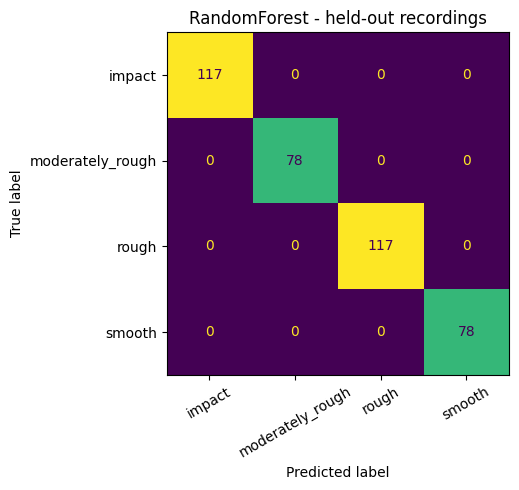

Per-speed performance (test):


,speed,n,acc,f1_macro
0,0.3,156,1.0,1.0
1,0.6,39,1.0,1.0
2,1.0,195,1.0,1.0


Mean confidence: correct = 0.987, (no errors)


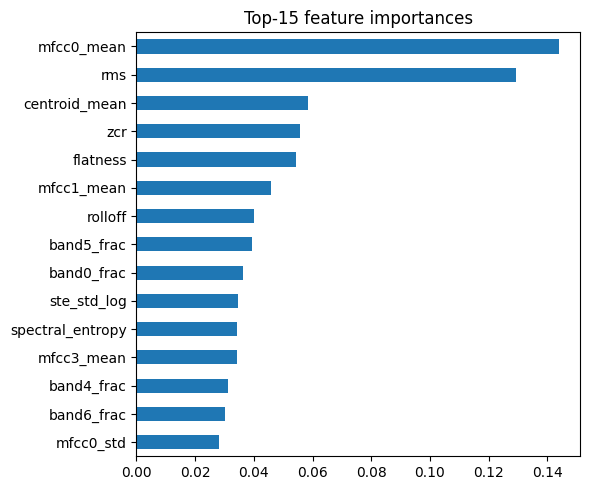

In [29]:
best = fitted[best_name]
pred = best.predict(Xte[cols])
print(classification_report(yte, pred, labels=range(len(le.classes_)), target_names=le.classes_, zero_division=0))
cm = confusion_matrix(yte, pred, labels=range(len(le.classes_)))
fig, ax = plt.subplots(figsize=(5.5, 5))
ConfusionMatrixDisplay(cm, display_labels=le.classes_).plot(ax=ax, xticks_rotation=30, colorbar=False)
ax.set_title(f"{best_name} - held-out recordings"); plt.tight_layout()
plt.savefig(f"{OUT_DIR}/confusion_matrix.png", dpi=150); plt.show()

# per-speed
spd = index.speed.values[test_idx]
if len(np.unique(spd[~np.isnan(spd)])) >= 2:
    ps = []
    for v in sorted(np.unique(spd[~np.isnan(spd)])):
        mk = spd == v
        ps.append(dict(speed=v, n=int(mk.sum()), acc=accuracy_score(yte[mk], pred[mk]),
                       f1_macro=f1_score(yte[mk], pred[mk], average="macro", labels=np.unique(yte[mk]), zero_division=0)))
    ps = pd.DataFrame(ps).round(4); ps.to_csv(f"{OUT_DIR}/per_speed.csv", index=False)
    print("Per-speed performance (test):"); display(ps)
else:
    print("Per-speed report skipped: add spd<value> to filenames (>=2 distinct speeds).")

# confidence (needed later by fusion / attribution)
conf = best.predict_proba(Xte[cols]).max(axis=1); ok = pred == yte
print(f"Mean confidence: correct = {conf[ok].mean():.3f}" + (f", wrong = {conf[~ok].mean():.3f}" if (~ok).any() else ", (no errors)"))

if best_name in ("RandomForest", "XGBoost"):
    imp = pd.Series(best.feature_importances_, index=cols).sort_values(ascending=False).head(15)
    imp.iloc[::-1].plot.barh(figsize=(6, 5), title="Top-15 feature importances"); plt.tight_layout(); plt.show()

## 12. R3: robustness to noise (test windows only; features re-extracted)

In [30]:
rng = np.random.default_rng(SEED)
te_index = index.iloc[test_idx].reset_index(drop=True)
sub = np.arange(len(te_index)) if len(te_index) <= 1500 else rng.choice(len(te_index), 1500, replace=False)
rows = []
for kind in ["white", "motor_hum"]:
    for snr in [None, 20, 10, 5, 0]:
        Xn = []
        for i in sub:
            w = get_window(te_index.rec[i], te_index.start[i])
            if snr is not None: w = add_noise(w, snr, kind, rng)
            Xn.append(rf.extract_features(w))
        r = prf(yte[sub], best.predict(pd.DataFrame(Xn)[cols]))
        rows.append(dict(noise=kind, snr_db="clean" if snr is None else snr, **r))
r3 = pd.DataFrame(rows).round(4)
r3.to_csv(f"{OUT_DIR}/R3_noise_robustness.csv", index=False)
display(r3)

,noise,snr_db,acc,precision,recall,f1
0,white,clean,1.0000,1.0000,1.0000,1.0000
1,white,20,1.0000,1.0000,1.0000,1.0000
2,white,10,1.0000,1.0000,1.0000,1.0000
3,white,5,1.0000,1.0000,1.0000,1.0000
4,white,0,0.7256,0.7980,0.6613,0.6033
5,motor_hum,clean,1.0000,1.0000,1.0000,1.0000
6,motor_hum,20,1.0000,1.0000,1.0000,1.0000
7,motor_hum,10,1.0000,1.0000,1.0000,1.0000
8,motor_hum,5,1.0000,1.0000,1.0000,1.0000
9,motor_hum,0,0.9308,0.9256,0.9402,0.9272


## 13. Save model bundle

In [31]:
RETRAIN_ON_ALL = False   # True once satisfied: refit on train+test windows
if RETRAIN_ON_ALL:
    Xa, ya = train_data(np.arange(len(X_df)), cols)
    final = clone(MODELS[best_name]).fit(Xa, ya)
else:
    final = best
bundle = dict(model=final, label_encoder=le, feature_names=cols, model_name=best_name,
              config=dict(sr=SR, win_s=WIN_S, hop_s=HOP_S, n_fft=rf.N_FFT, hop=rf.HOP, highpass_hz=50,
                          normalize=NORMALIZE, augment=AUGMENT, dropped_loudness=DROP_LOUDNESS_FOR_FINAL,
                          classes=[str(c) for c in le.classes_], trained_on_synthetic=USE_SYNTHETIC))
joblib.dump(bundle, f"{OUT_DIR}/road_model.pkl")
print("Saved road_model.pkl + road_features.py in", OUT_DIR)

# serving-style check using the shared module
b = joblib.load(f"{OUT_DIR}/road_model.pkl")
label, probs = rf.predict_window(b, get_window(index.rec[0], index.start[0]))
print("Example:", label, {k: round(v, 3) for k, v in probs.items()}, "| true:", index.label[0])

Saved road_model.pkl + road_features.py in /content/road_model_out
Example: smooth {np.str_('impact'): 0.0, np.str_('moderately_rough'): 0.0, np.str_('rough'): 0.0, np.str_('smooth'): 1.0} | true: smooth


In [32]:
try:
    from google.colab import files
    shutil.make_archive("/content/road_model_results", "zip", OUT_DIR)
    files.download("/content/road_model_results.zip")
except ImportError:
    print("Not in Colab; results are in", OUT_DIR)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [33]:
# STAGE-2 FINE-TUNING / TARGET-DOMAIN ADAPTATION CELL (Run once you have real RC-Car WAV files)
RC_DATA_ROOT = "/content/rc_audio"  # Folder with your real ESP32 + INMP441 WAV recordings

if os.path.isdir(RC_DATA_ROOT):
    rc_rows, rc_feats = [], []
    for c in classes:
        for f in sorted(glob.glob(f"{RC_DATA_ROOT}/{c}/*.wav")):
            rid = f"rc_{c}/{os.path.basename(f)}"
            y_raw, _ = librosa.load(f, sr=SR, mono=True)
            y_pp = rf.preprocess(y_raw, SR, NORMALIZE)
            for s in window_starts(len(y_pp)):
                rc_rows.append((rid, c))
                rc_feats.append(rf.extract_features(y_pp[s:s+int(WIN_S*SR)]))

    rc_index = pd.DataFrame(rc_rows, columns=["rec", "label"])
    X_rc = pd.DataFrame(rc_feats)[cols]
    y_rc = le.transform(rc_index.label.values)
    g_rc = rc_index.rec.values

    # Split RC runs into 70% Adaptation-Train and 30% Held-out RC-Test (by recording!)
    sgkf_rc = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEED)
    rc_tr, rc_te = next(sgkf_rc.split(X_rc, y_rc, g_rc))

    # 1. BEFORE ADAPTATION (Stage-1 model tested directly on RC Car)
    before_scores = prf(y_rc[rc_te], best.predict(X_rc.iloc[rc_te]))
    print("Before RC Adaptation (Stage-1 Model):", before_scores)

    # 2. FINE-TUNE / ADAPT (Combine Stage-1 data + upweighted RC Car training data)
    X_comb = pd.concat([X_df.iloc[trainval_idx][cols], X_rc.iloc[rc_tr]], ignore_index=True)
    y_comb = np.concatenate([y[trainval_idx], y_rc[rc_tr]])
    # Give real RC-car windows 5x higher weight than Stage-1 data so the model adapts to RC acoustics
    weights = np.concatenate([np.ones(len(trainval_idx)), np.full(len(rc_tr), 5.0)])

    adapted_model = clone(MODELS[best_name])
    if best_name == "SVM_RBF":
        adapted_model.fit(X_comb, y_comb, svc__sample_weight=weights)
    else:
        adapted_model.fit(X_comb, y_comb, sample_weight=weights)

    # 3. AFTER ADAPTATION (Evaluated on held-out RC Car recordings)
    after_scores = prf(y_rc[rc_te], adapted_model.predict(X_rc.iloc[rc_te]))
    print("After RC Adaptation (Fine-Tuned Model):", after_scores)

    # Save updated RC-adapted road_model.pkl for FastAPI
    bundle["model"] = adapted_model
    joblib.dump(bundle, f"{OUT_DIR}/road_model.pkl")
    print("Updated road_model.pkl with RC-Car fine-tuned model!")